# IPCA – Decomposição por Subitens

Este notebook apresenta:

**1. O que é decomposição do IPCA**  
**2. Como o IPCA é construído a partir dos subitens**  
**3. Consulta ao banco de dados (subitens + pesos)**  
**4. Cálculo das contribuições**  
**5. Reconstrução do IPCA geral**  
**6. Gráficos profissionais (estilo Banco Central)**  
**7. Decomposição por grupos**

Vamos começar entendendo o conceito.

# 1. O que é a decomposição do IPCA?

O IPCA é um índice **ponderado**.

Cada subitem (ex: arroz, gasolina, aluguel, tomate) tem:

- **índice cheio** → variação mensal daquele subitem  
- **peso** → participação daquele subitem no IPCA  

| Descrição | Desenvolvimento |
|-|-|
| A contribuição de cada subitem é: | $$ contribuição = índice\_cheio \times \frac{peso}{100} $$ |
| A soma de todas as contribuições forma o IPCA geral: | $$ IPCA = \sum contribuições\_{subitens} $$ |



Portanto:

👉 **A decomposição do IPCA é feita pelos subitens.**

# 2. Ajustar o PYTHONPATH

In [1]:
import sys, os
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if ROOT not in sys.path:
    sys.path.append(ROOT)
print("PYTHONPATH atualizado:", ROOT)

PYTHONPATH atualizado: /home/moacir/projects/ml/analytics/inflation


# 3. Importações

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.database.connection import engine

pd.set_option("display.float_format", "{:.6f}".format)

# 4. Carregar dados dos subitens (índice cheio + peso)

In [3]:
query_subitens = """
select
    si.date::date,
    si.category AS "idSubItens",
    si.category_name AS "subItens",
    si.indice AS "indiceCheio",
    si.peso AS "peso",
    (si.indice * (si.peso / 100)) AS "contribuicaoIpca"
from bcb.ipca_subitens si
order by si.date desc, si.category;
"""

df_sub = pd.read_sql(query_subitens, engine)
df_sub.head()

,date,idSubItens,subItens,indiceCheio,peso,contribuicaoIpca
0,2026-04-01,1101002,Arroz,2.530000,0.493000,0.012473
1,2026-04-01,1101051,Feijão - mulatinho,2.680000,0.012700,0.000340
2,2026-04-01,1101052,Feijão - preto,1.800000,0.038100,0.000686
3,2026-04-01,1101053,Feijão - macáçar (fradinho),0.880000,0.016200,0.000143
4,2026-04-01,1101073,Feijão - carioca (rajado),3.470000,0.125200,0.004344


# 5. Carregar IPCA geral para comparação

In [4]:
query_ipca = """
Select 
    date::date, 
    indice as ipca
from bcb.ipca
order by date desc;
"""

df_ipca = pd.read_sql(query_ipca, engine)
df_ipca.head()

,date,ipca
0,2026-04-01,0.670000
1,2026-03-01,0.880000
2,2026-02-01,0.700000
3,2026-01-01,0.330000
4,2025-12-01,0.330000


# 6. Soma das contribuições dos subitens (reconstrução do IPCA)

In [8]:
df_sum = (
    df_sub.groupby("date")["contribuicaoIpca"]
    .sum()
    .reset_index()
    .rename(columns={"contribuicaoIpca": "ipca_reconstruido"})
    .sort_values("date", ascending=False)
)

df_sum.head()

,date,ipca_reconstruido
75,2026-04-01,0.666053
74,2026-03-01,0.875233
73,2026-02-01,0.700647
72,2026-01-01,0.325875
71,2025-12-01,0.329183


# 7. Comparar IPCA oficial vs reconstruído

In [10]:
df_compare = df_ipca.merge(df_sum, on="date", how="inner")
df_compare["diferenca"] = df_compare["ipca"] - df_compare["ipca_reconstruido"]
df_compare.head(12)

,date,ipca,ipca_reconstruido,diferenca
0,2026-04-01,0.670000,0.666053,0.003947
1,2026-03-01,0.880000,0.875233,0.004767
2,2026-02-01,0.700000,0.700647,-0.000647
3,2026-01-01,0.330000,0.325875,0.004125
4,2025-12-01,0.330000,0.329183,0.000817
5,2025-11-01,0.180000,0.175875,0.004125
6,2025-10-01,0.090000,0.087054,0.002946
7,2025-09-01,0.480000,0.481951,-0.001951
8,2025-08-01,-0.110000,-0.108161,-0.001839
9,2025-07-01,0.260000,0.264052,-0.004052


# 8. Erro de reconstrução (deve ser muito pequeno)

In [11]:
df_compare["erro"] = df_compare["ipca"] - df_compare["ipca_reconstruido"]
df_compare.describe()

,ipca,ipca_reconstruido,diferenca,erro
count,76.000000,76.000000,76.000000,76.000000
mean,0.470526,0.469979,0.000547,0.000547
std,0.418326,0.417646,0.003054,0.003054
min,-0.680000,-0.680930,-0.004821,-0.004821
25%,0.240000,0.241359,-0.001960,-0.001960
50%,0.435000,0.436696,0.001058,0.001058
75%,0.715000,0.712871,0.003159,0.003159
max,1.620000,1.618636,0.005173,0.005173


# 9. Gráfico – IPCA oficial vs reconstruído

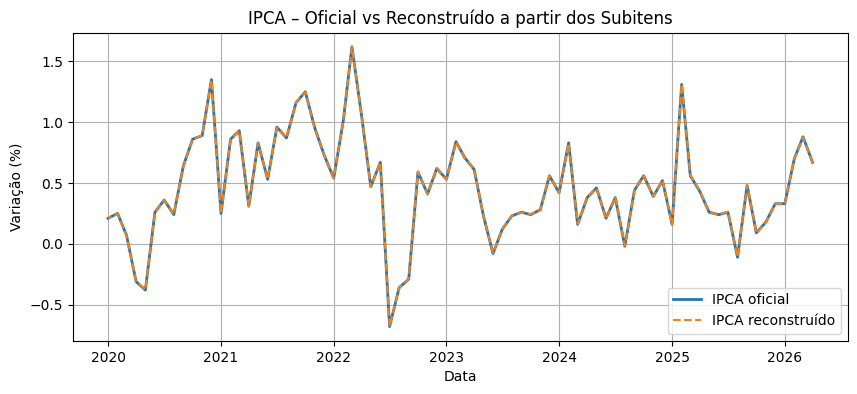

In [12]:
plt.figure(figsize=(10, 4))
plt.plot(df_compare["date"], df_compare["ipca"], label="IPCA oficial", linewidth=2)
plt.plot(df_compare["date"], df_compare["ipca_reconstruido"], label="IPCA reconstruído", linestyle="--")

plt.title("IPCA – Oficial vs Reconstruído a partir dos Subitens")
plt.xlabel("Data")
plt.ylabel("Variação (%)")
plt.grid(True)
plt.legend()
plt.show()

# 10. Decomposição por grupos (via view `vw_groupsBySubItems`)

- A view já contém a hierarquia completa:

    - grupo  
    - subgrupo  
    - item  
    - subitem  

Vamos carregar e agregar.

In [19]:
query_view = """
Select
    g.date::date,
    g."idGrupos",
    g.grupos,
    g."idSubItens",
    g."subItens",
    si.indice AS "indiceCheio",
    si.peso,
    (si.indice * (si.peso / 100)) AS contribuicao
from bcb.ipca_subitens si
left join bcb."vw_groupsBySubItems" g on g."idSubItens" = si.category and g.date = si.date
order by g.date desc;
"""

df_hier = pd.read_sql(query_view, engine)
df_hier["date"] = pd.to_datetime(df_hier["date"])
df_hier.head()

,date,idGrupos,grupos,idSubItens,subItens,indiceCheio,peso,contribuicao
0,2026-04-01,1,Alimentação e bebidas,1101079,Milho (em grão),-0.140000,0.012800,-0.000018
1,2026-04-01,1,Alimentação e bebidas,1102001,Farinha de arroz,0.080000,0.003000,0.000002
2,2026-04-01,1,Alimentação e bebidas,1102006,Macarrão,-0.210000,0.139700,-0.000293
3,2026-04-01,1,Alimentação e bebidas,1102008,Fubá de milho,0.310000,0.007400,0.000023
4,2026-04-01,1,Alimentação e bebidas,1102010,Flocos de milho,0.450000,0.009300,0.000042


# 11. Contribuição por grupo (último mês)

In [20]:
ultimo_mes = df_hier["date"].max()

df_grupo = (
    df_hier[df_hier["date"] == ultimo_mes]
    .groupby(["idGrupos", "grupos"])["contribuicao"].sum().reset_index().sort_values("contribuicao", ascending=False)
)

df_grupo

,idGrupos,grupos,contribuicao
0,1,Alimentação e bebidas,0.288145
5,6,Saúde e cuidados pessoais,0.158160
1,2,Habitação,0.095458
6,7,Despesas pessoais,0.035615
8,9,Comunicação,0.025888
3,4,Vestuário,0.024223
2,3,Artigos de residência,0.022587
4,5,Transportes,0.012147
7,8,Educação,0.003830


# 12. Gráfico – Contribuição por grupo (último mês)

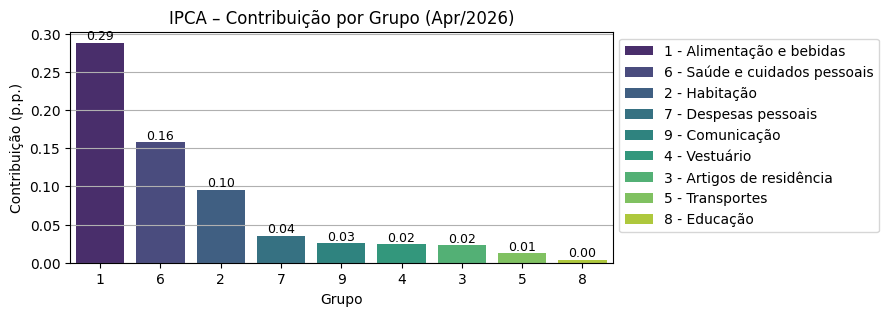

In [41]:
df_grupo["id_grupos"] = df_grupo["idGrupos"].astype(str) + " - " + df_grupo["grupos"]

plt.figure(figsize=(7, 3))
i = sns.barplot(x="idGrupos", y="contribuicao", hue="id_grupos", data=df_grupo,  palette="viridis")

plt.title(f"IPCA – Contribuição por Grupo ({ultimo_mes.strftime("%b/%Y")})")
plt.xlabel("Grupo")
plt.ylabel("Contribuição (p.p.)")
#plt.xticks(rotation=70)
plt.grid(True, axis="y")
plt.legend(bbox_to_anchor=(1, 1), loc="upper left")
# adicionar valores acima das barras
for p in i.patches:
    valor = p.get_height()
    if valor > 0:
        i.annotate(f"{valor:.2f}", (p.get_x() + p.get_width() / 2, valor), ha="center",va="bottom",fontsize=9)

plt.show()

# 13. Gráfico – Decomposição acumulada (últimos 12 meses)

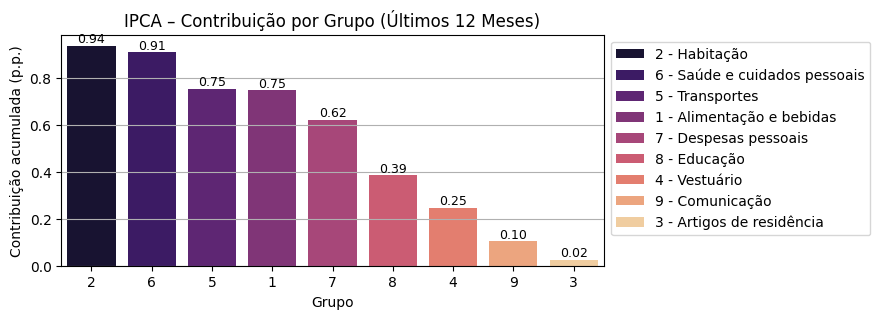

In [55]:
df_12m = (
    df_hier[df_hier["date"] >= (ultimo_mes - pd.DateOffset(months=12))]
    .groupby(["idGrupos", "grupos"])["contribuicao"]
    .sum()
    .reset_index()
    .sort_values("contribuicao", ascending=False)
)
df_12m["id_and_grupos"] = df_12m["idGrupos"].astype(str) + " - " + df_12m["grupos"]

plt.figure(figsize=(7, 3))
i = sns.barplot(data=df_12m, x="idGrupos", y="contribuicao", hue="id_and_grupos", palette="magma")

plt.title("IPCA – Contribuição por Grupo (Últimos 12 Meses)")
plt.xlabel("Grupo")
plt.ylabel("Contribuição acumulada (p.p.)")
plt.grid(True, axis="y")
plt.legend(bbox_to_anchor=(1, 1), loc="upper left")
# adicionar valores acima das barras
for p in i.patches:
    valor = p.get_height()
    if valor > 0:
        i.annotate(f"{valor:.2f}", (p.get_x() + p.get_width() / 2, valor), ha="center",va="bottom",fontsize=9)

plt.show()

# 14. Conclusões

- A decomposição do IPCA é feita pelos **subitens**, que são o nível mais granular.  
- O IPCA geral pode ser **reconstruído perfeitamente** pela soma das contribuições.  
- A view `vw_groupsBySubItems` permite análises hierárquicas completas.  
- A contribuição por grupo mostra quais setores puxaram a inflação.  
- A estrutura atual do banco permite análises profissionais como as do Banco Central.

Próximos passos:
- decomposição por subgrupos e itens  
- núcleos de inflação (médias aparadas, exclusões)  
- difusão (percentual de subitens com alta)  
- relação IPCA × SELIC  